# Monte Carlo Stock Price & Portfolio Risk Simulator

This notebook simulates future equity prices using Geometric Brownian Motion (GBM). It starts with a single stock (AAPL): estimating historical return/volatility parameters, simulating thousands of possible price paths, and measuring downside risk with VaR/CVaR. It then extends the same approach to a 4-asset portfolio (AAPL, GS, JPM, MSFT), accounting for how the assets' returns move together.

In [35]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


## Step 1: Pull historical data & estimate GBM parameters

Download 2 years of daily AAPL closing prices, compute daily log returns, and estimate the mean daily return and daily volatility from history — these are the drift and diffusion parameters the GBM simulation needs.

[*********************100%***********************]  1 of 1 completed

Ticker: AAPL
Data points: 2512
Mean daily return: 0.00103
Daily volatility: 0.01833
Latest close price: $338.40


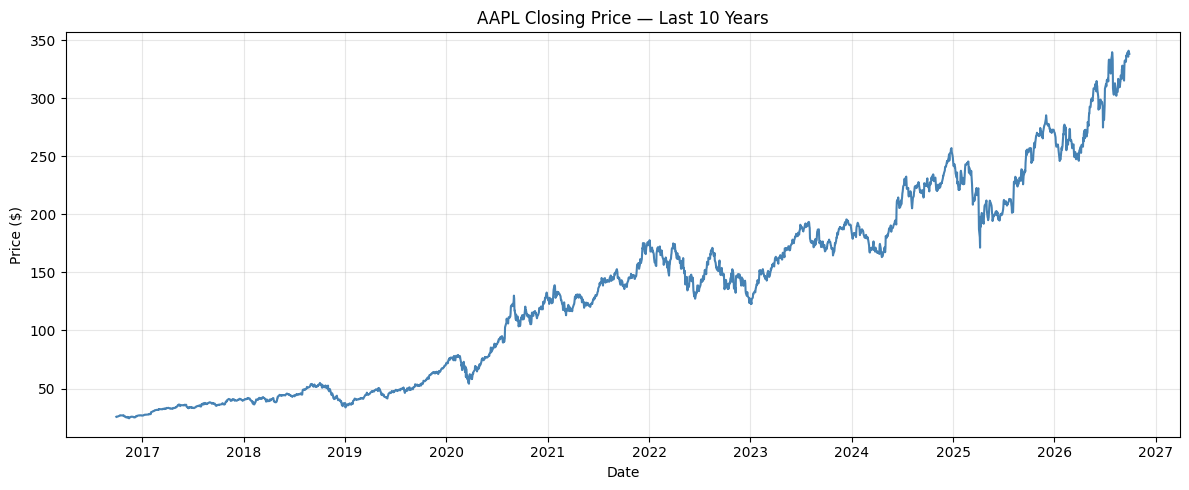

In [36]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pull 10 years of Apple stock data
ticker = "AAPL"
data_aapl = yf.download(ticker, period="10y", auto_adjust=True)
prices = data_aapl['Close']

# Calculate daily returns
log_returns_aapl = np.log(prices / prices.shift(1))

# Estimate mean daily return and daily volatility from historical data
mean_return = log_returns_aapl.mean().item()
volatility = log_returns_aapl.std().item()

print(f"Ticker: {ticker}")
print(f"Data points: {len(prices)}")
print(f"Mean daily return: {mean_return:.5f}")
print(f"Daily volatility: {volatility:.5f}")
print(f"Latest close price: ${prices.iloc[-1].item():.2f}")

# Quick plot
plt.figure(figsize=(12, 5))
plt.plot(prices, color='steelblue')
plt.title(f'{ticker} Closing Price — Last 10 Years')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
num_simulations = 1000
num_days = 252  # Number of trading days in a year

## Step 2: Simulate future price paths (loop-based GBM)

For each of `num_simulations` hypothetical futures, walk forward day by day: draw a random standard-normal shock, apply the GBM daily return formula `(mean_return - 0.5*volatility**2) + volatility*Z`, and compound it onto the running price. This is the straightforward but slow way to generate simulated price paths.

In [38]:
# Monte Carlo simulation using GBM
prices_aapl = data_aapl['Close'].dropna()
num_simulations = 10000   # number of possible future paths to simulate
num_days = 252            # trading days in ~1 year — our forecast horizon

last_price = prices.iloc[-1].item()

# Matrix to hold all simulated price paths
simulation_results = np.zeros((num_days, num_simulations))

for sim in range(num_simulations):
    price_series = [last_price]
    for day in range(num_days):
        Z = np.random.normal(0, 1)  # random shock for this day
        daily_return = (mean_return - 0.5 * volatility**2) + volatility * Z
        new_price = price_series[-1] * np.exp(daily_return)
        price_series.append(new_price)
    simulation_results[:, sim] = price_series[1:]

print(f"Simulated {num_simulations} paths over {num_days} trading days")
print(f"Starting price: ${last_price:.2f}")
print(f"Mean ending price: ${simulation_results[-1].mean():.2f}")
print(f"Min ending price: ${simulation_results[-1].min():.2f}")
print(f"Max ending price: ${simulation_results[-1].max():.2f}")

Simulated 10000 paths over 252 trading days
Starting price: $338.40
Mean ending price: $438.12
Min ending price: $135.92
Max ending price: $1332.34


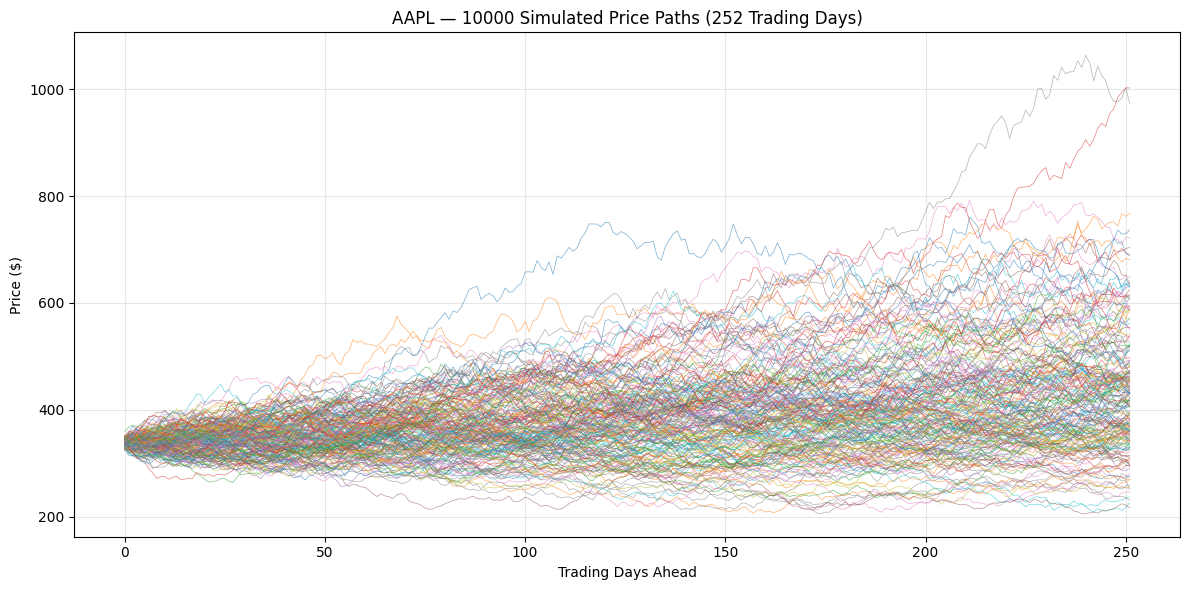

In [39]:
# Plot a sample of simulated paths
plt.figure(figsize=(12, 6))
plt.plot(simulation_results[:, :200], linewidth=0.5, alpha=0.6)  # plot first 200 paths
plt.title(f'{ticker} — {num_simulations} Simulated Price Paths ({num_days} Trading Days)')
plt.xlabel('Trading Days Ahead')
plt.ylabel('Price ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 3: Quantify downside risk (VaR & CVaR)

Convert the simulated ending prices into simple returns, then compute the 95% Value at Risk (the return threshold the worst 5% of outcomes fall below) and Conditional VaR (the average return within that worst 5% tail).

In [40]:
ending_prices = simulation_results[-1, :]
returns_simulated = (ending_prices - last_price) / last_price

confidence_level = 0.95
VaR_95 = np.percentile(returns_simulated, 5)
CVaR_95 = returns_simulated[returns_simulated <= VaR_95].mean()

print(f"Value at Risk (95% confidence): {VaR_95:.2%}")
print(f"Conditional Value at Risk (95% confidence): {CVaR_95:.2%}")

Value at Risk (95% confidence): -22.43%
Conditional Value at Risk (95% confidence): -30.79%


## Step 4: Vectorize the simulation

The double `for` loop above is slow at scale. Here the same GBM math is applied to every simulation and every day at once using NumPy array operations, producing statistically identical results in a fraction of the time.

In [41]:
# Vectorized Monte Carlo simulation using GBM

num_simulations = 10000   # number of possible future paths to simulate
num_days = 252

#Generating random shocks for all simulations at once
Z = np.random.normal(0,1, size=(num_days, num_simulations))

# Calculate daily returns for all simulations
daily_returns = (mean_return - 0.5 * volatility**2) + volatility * Z


# Cumulative returns for all simulations
cumulative_log_returns = np.cumsum(daily_returns, axis=0)

# Simulated price paths
simulation_results_vectorized = last_price * np.exp(cumulative_log_returns)

print(f'Mean ending price (vectorized): ${simulation_results_vectorized[-1].mean():.2f}')
print(f'Min ending price (vectorized): ${simulation_results_vectorized[-1].min():.2f}')
print(f'Max ending price (vectorized): ${simulation_results_vectorized[-1].max():.2f}')


Mean ending price (vectorized): $439.73
Min ending price (vectorized): $125.57
Max ending price (vectorized): $1405.94


## Step 5: Extend to a multi-asset portfolio

The single-stock model above only accounts for one source of risk. To simulate a realistic portfolio we need historical data for multiple tickers and a way to capture how their returns move together — that means computing a covariance/correlation matrix instead of a single volatility number.

In [42]:
tickers = ['AAPL', 'GS', 'JPM', 'MSFT']
data_portfolio = yf.download(tickers, period="10y", auto_adjust=True)
log_returns_portfolio = np.log(data_portfolio['Close'] / data_portfolio['Close'].shift(1))
cov_matrix = log_returns_portfolio.cov()
correlation_matrix = log_returns_portfolio.corr()
print("Covariance Matrix:")
print(cov_matrix)


#Finding the correlation between the stocks
correlation_matrix = log_returns_portfolio.corr()
print("Correlation Matrix:")
print(correlation_matrix)


[*********************100%***********************]  4 of 4 completed

Covariance Matrix:
Ticker      AAPL        GS       JPM      MSFT
Ticker                                        
AAPL    0.000336  0.000157  0.000127  0.000204
GS      0.000157  0.000361  0.000263  0.000146
JPM     0.000127  0.000263  0.000297  0.000120
MSFT    0.000204  0.000146  0.000120  0.000305
Correlation Matrix:
Ticker      AAPL        GS       JPM      MSFT
Ticker                                        
AAPL    1.000000  0.452342  0.403752  0.637009
GS      0.452342  1.000000  0.803977  0.440171
JPM     0.403752  0.803977  1.000000  0.399015
MSFT    0.637009  0.440171  0.399015  1.000000


## Portfolio Monte Carlo (4 assets, correlated)

Simulating each stock independently would ignore the fact that AAPL, GS, JPM, and MSFT don't move in isolation — the correlation matrix above shows GS and JPM are especially tied together (~0.77), likely from shared exposure to financial-sector and macro factors. If we generated independent random shocks per asset, the simulated portfolio would look far more diversified — and far less risky — than reality. So we use a Cholesky decomposition of the covariance matrix to inject the observed correlations into the simulated shocks before compounding them into price paths.

In [43]:
# Step 2: Per-asset mean daily return and volatility (as pandas Series, one column per ticker)
mean_returns = log_returns_portfolio.mean()
volatilities = log_returns_portfolio.std()

print("Mean Returns:")
print(mean_returns)
print("Volatilities:")
print(volatilities)

# Step 3: Cholesky decomposition of the covariance matrix.
# L is lower-triangular such that L @ L.T == cov_matrix; multiplying independent shocks
# by L.T injects the observed correlations between assets into the simulation.
L = np.linalg.cholesky(cov_matrix)

Mean Returns:
Ticker
AAPL    0.001027
GS      0.000780
JPM     0.000756
MSFT    0.000917
dtype: float64
Volatilities:
Ticker
AAPL    0.018331
GS      0.018987
JPM     0.017222
MSFT    0.017459
dtype: float64


In [44]:
num_simulations = 10000
num_days = 252

# Step 4: Generate independent standard normal shocks, one per asset per simulated day
Z = np.random.normal(size=(num_days, num_simulations, 4))

# Correlate the shocks using the Cholesky factor so simulated assets move together realistically
correlated_Z = Z @ L.T

# Step 5: Daily log returns per asset, including the GBM drift term (-0.5 * volatility^2).
# Note: correlated_Z already carries each asset's volatility, because L was derived from
# cov_matrix (variance units), not correlation_matrix -- so we add it directly rather than
# multiplying by volatilities again (that would double-apply vol and crush the variance).
daily_log_returns = (mean_returns.values - 0.5 * volatilities.values**2) + correlated_Z

# Step 6: Cumulative log returns over the simulation horizon
cumulative_log_returns = np.cumsum(daily_log_returns, axis=0)

In [45]:
# Step 7: Starting price for each ticker — last row of the 4-ticker Close price data pulled above
start_prices = data_portfolio['Close'].dropna().iloc[-1].values  # shape (4,), order: AAPL, GS, JPM, MSFT

# Step 8: Convert cumulative log returns back into simulated price paths, shape (num_days, num_simulations, 4)
simulated_prices = start_prices * np.exp(cumulative_log_returns)

In [46]:
print("start_prices:", start_prices)
print("any NaN in start_prices:", np.isnan(start_prices).any())

print("simulated_prices shape:", simulated_prices.shape)
print("any NaN in simulated_prices:", np.isnan(simulated_prices).any())

print("correlated_shocks any NaN:", np.isnan(correlated_Z).any())
print("cumulative_log_returns any NaN:", np.isnan(cumulative_log_returns).any())

print("mean_returns:", mean_returns)
print("volatilities:", volatilities)
print("cov_matrix:\n", cov_matrix)

start_prices: [338.3999939  916.2800293  336.58999634 509.22000122]
any NaN in start_prices: False
simulated_prices shape: (252, 10000, 4)
any NaN in simulated_prices: False
correlated_shocks any NaN: False
cumulative_log_returns any NaN: False
mean_returns: Ticker
AAPL    0.001027
GS      0.000780
JPM     0.000756
MSFT    0.000917
dtype: float64
volatilities: Ticker
AAPL    0.018331
GS      0.018987
JPM     0.017222
MSFT    0.017459
dtype: float64
cov_matrix:
 Ticker      AAPL        GS       JPM      MSFT
Ticker                                        
AAPL    0.000336  0.000157  0.000127  0.000204
GS      0.000157  0.000361  0.000263  0.000146
JPM     0.000127  0.000263  0.000297  0.000120
MSFT    0.000204  0.000146  0.000120  0.000305


In [47]:
print("start_prices shape:", start_prices.shape)
print("cumulative_log_returns shape:", cumulative_log_returns.shape)

start_prices shape: (4,)
cumulative_log_returns shape: (252, 10000, 4)


In [48]:
start_prices = data_portfolio['Close'].dropna().iloc[-1].values

# Step 9: Simple per-asset returns relative to the starting price, combined into an equal-weighted portfolio
asset_returns = simulated_prices / start_prices - 1  # (num_days, num_simulations, 4)
weights = np.array([0.25, 0.25, 0.25, 0.25])  # AAPL, GS, JPM, MSFT
portfolio_returns = asset_returns @ weights  # (num_days, num_simulations)

# Step 10: Portfolio value over time, summary stats, and VaR/CVaR risk metrics on the final day
portfolio_value = 10000 * (1 + portfolio_returns)  # starting portfolio value = $10,000
ending_values = portfolio_value[-1]

print(f"Mean ending portfolio value: ${ending_values.mean():.2f}")
print(f"5th percentile ending value: ${np.percentile(ending_values, 5):.2f}")
print(f"95th percentile ending value: ${np.percentile(ending_values, 95):.2f}")

final_day_returns = portfolio_returns[-1]
VaR_95 = np.percentile(final_day_returns, 5)
CVaR_95 = final_day_returns[final_day_returns <= VaR_95].mean()

print(f"Portfolio Value at Risk (95% confidence): {VaR_95:.2%}")
print(f"Portfolio Conditional Value at Risk (95% confidence): {CVaR_95:.2%}")

Mean ending portfolio value: $12479.03
5th percentile ending value: $8362.28
95th percentile ending value: $17778.57
Portfolio Value at Risk (95% confidence): -16.38%
Portfolio Conditional Value at Risk (95% confidence): -23.87%


In [49]:
simple_returns = np.exp(log_returns_portfolio) - 1
historical_portfolio_returns = simple_returns @ weights   # daily portfolio returns (real data)

rolling_252d_returns = (1 + historical_portfolio_returns).rolling(252).apply(np.prod, raw=True) - 1
rolling_252d_returns = rolling_252d_returns.dropna()

non_overlapping = rolling_252d_returns.iloc[::252]
breaches = non_overlapping[non_overlapping < VaR_95]
print(f"Non-overlapping windows: {len(non_overlapping)}")
print(f"Breaches: {len(breaches)} ({len(breaches)/len(non_overlapping):.1%})")
print(f"Number of VaR breaches in historical data: {breaches.sum()}")
print(f"Breach rate: {breaches.sum()/len(rolling_252d_returns):.2%}  (expected: ~5.00%)")

Non-overlapping windows: 9
Breaches: 1 (11.1%)
Number of VaR breaches in historical data: -0.16960521180268107
Breach rate: -0.01%  (expected: ~5.00%)


In [50]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(log_returns_portfolio['AAPL'].dropna(), order=(1, 0, 1))
fitted_model = model.fit()
print(fitted_model.summary())

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 2511
Model:                 ARIMA(1, 0, 1)   Log Likelihood                6484.238
Date:                Mon, 28 Sep 2026   AIC                         -12960.476
Time:                        22:11:01   BIC                         -12937.162
Sample:                             0   HQIC                        -12952.014
                               - 2511                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.000      2.864      0.004       0.000       0.002
ar.L1         -0.4348      0.161     -2.698      0.007      -0.751      -0.119
ma.L1          0.3775      0.165      2.290      0.0

In [51]:
# Calculate simple returns from historical log returns (convert from log to simple)
simple_returns = np.exp(log_returns_portfolio) - 1

# Rolling 252-day cumulative historical portfolio returns
historical_portfolio_returns = simple_returns @ weights   # daily portfolio returns (real data)
rolling_252d_returns = (1 + historical_portfolio_returns).rolling(252).apply(np.prod, raw=True) - 1
rolling_252d_returns = rolling_252d_returns.dropna()

breaches = rolling_252d_returns < VaR_95
print(f"Number of 252-day windows: {len(rolling_252d_returns)}")
print(f"Number of VaR breaches: {breaches.sum()}")
print(f"Breach rate: {breaches.sum()/len(rolling_252d_returns):.2%}  (expected: ~5.00%)")

Number of 252-day windows: 2260
Number of VaR breaches: 35
Breach rate: 1.55%  (expected: ~5.00%)


In [52]:
## Step 4: Fat-tailed shocks (Student-t vs Normal)
from scipy import stats

# Student-t shocks instead of Normal
degrees_of_freedom = 5
Z_t = stats.t.rvs(df=degrees_of_freedom, size=(num_days, num_simulations, 4))

# Rescaling 
scaling_factor = np.sqrt((degrees_of_freedom - 2) / degrees_of_freedom)
Z_t_scaled = Z_t * scaling_factor
print(Z_t_scaled.var())

1.0012871506312018


In [53]:
# Correlating the fat tailed shocks
correlated_Z_t = Z_t_scaled @ L.T

# Same GBM formula with fat-tailed shocks
daily_log_returns_t = (mean_returns.values - 0.5 * volatilities.values**2) + correlated_Z_t

cumulative_log_returns_t = np.cumsum(daily_log_returns_t, axis=0)
simulated_prices_t = start_prices * np.exp(cumulative_log_returns_t)

asset_returns_t = simulated_prices_t / start_prices - 1
portfolio_returns_t = asset_returns_t @ weights
portfolio_value_t = 10000 * (1 + portfolio_returns_t)

final_day_returns_t = portfolio_returns_t[-1]
VaR_95_t = np.percentile(final_day_returns_t, 5)
CVaR_95_t = final_day_returns_t[final_day_returns_t <= VaR_95_t].mean()

print(f"Student-t VaR (95%): {VaR_95_t:.2%}   (Normal VaR was {VaR_95:.2%})")
print(f"Student-t CVaR (95%): {CVaR_95_t:.2%}   (Normal CVaR was {CVaR_95:.2%})")

Student-t VaR (95%): -16.57%   (Normal VaR was -16.38%)
Student-t CVaR (95%): -24.10%   (Normal CVaR was -23.87%)


In [57]:
test_size = 100  # forecast horizon you're actually testing
train_size = len(prices_aapl) - test_size
train_returns = log_returns_aapl.iloc[:train_size]
test_returns = log_returns_aapl.iloc[train_size:]
train_prices = prices_aapl.iloc[:train_size]
test_prices = prices_aapl.iloc[train_size:]
print(f"Train: {len(train_returns)} days, Test: {len(test_returns)} days")

Train: 2412 days, Test: 100 days


In [58]:
model = ARIMA(train_returns['AAPL'].dropna(), order=(1, 0, 1))
fitted = model.fit()

forecasted_returns = fitted.forecast(steps=len(test_returns))

last_train_price = train_prices.iloc[-1].item()
forecast_prices = last_train_price * np.exp(forecasted_returns.cumsum())

print(forecast_prices.head())

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


2411    283.396630
2412    283.877955
2413    284.088050
2414    284.395707
2415    284.668795
Name: predicted_mean, dtype: float64


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


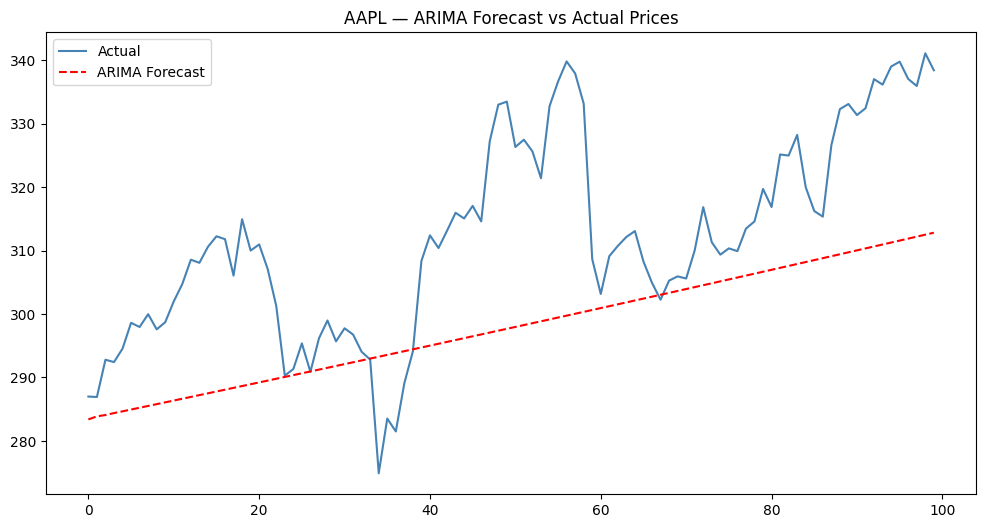

Root Mean Squared Error (RMSE) of ARIMA forecast: 22.74


In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(test_prices.values, label='Actual', color='steelblue')
plt.plot(forecast_prices.values, label='ARIMA Forecast', color='red', linestyle='--')
plt.legend()
plt.title(f'{ticker} — ARIMA Forecast vs Actual Prices')
plt.show()

rmse = np.sqrt(np.mean((forecast_prices.values - test_prices.values)**2))
print(f"Root Mean Squared Error (RMSE) of ARIMA forecast: {rmse:.2f}")